In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('marketing_AB_exp10.csv')
df.head()
df['test group'].value_counts()

,count
test group,
ad,564577
psa,23524


In [ ]:
rates = df.groupby('test group')['converted'].mean() * 100
print(rates.round(3))

test group
ad     2.555
psa    1.785
Name: converted, dtype: float64


In [ ]:
ad_rate = df[df['test group']=='ad']['converted'].mean()
psa_rate = df[df['test group']=='psa']['converted'].mean()

print('Absolute uplift (pp):', round((ad_rate - psa_rate)*100, 3))
print('Relative uplift (%):', round((ad_rate - psa_rate)/psa_rate*100, 1))

Absolute uplift (pp): 0.769
Relative uplift (%): 43.1


In [ ]:
contingency = pd.crosstab(df['test group'], df['converted'])
contingency

converted,False,True
test group,,
ad,550154,14423
psa,23104,420


In [ ]:
from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(contingency)
print('Chi-square statistic:', round(chi2, 2))
print('p-value:', p)
if p < 0.05:
   print('Significant: the difference is real.')
else:
   print('Not significant: could be chance.')

Chi-square statistic: 54.01
p-value: 1.9989623063390075e-13
Significant: the difference is real.


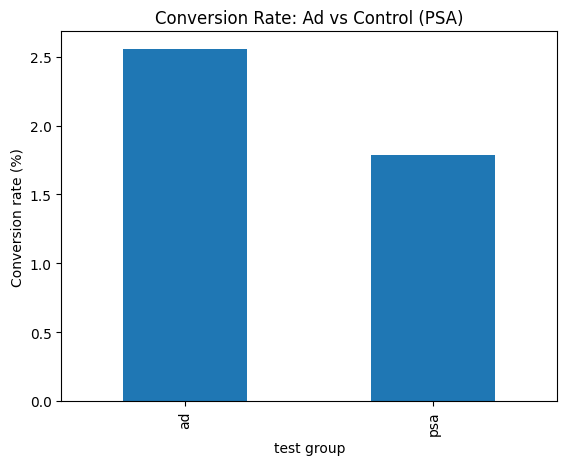

In [ ]:
import matplotlib.pyplot as plt
rates.plot(kind='bar')
plt.ylabel('Conversion rate (%)')
plt.title('Conversion Rate: Ad vs Control (PSA)')
plt.show()

Chi-square statistic: 54.01
p-value: 1.9989623063390075e-13
Significant: the difference is real.


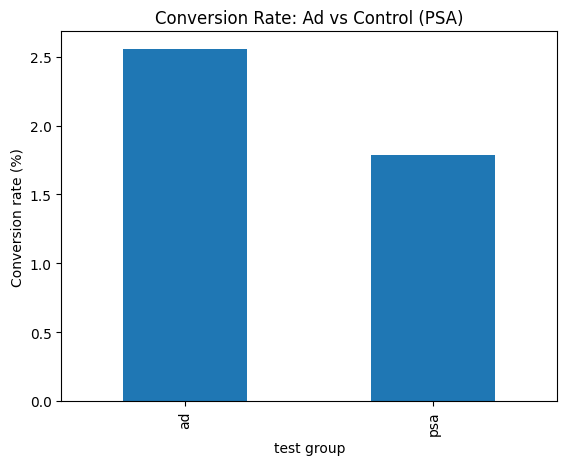

In [ ]:
from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(contingency)
print('Chi-square statistic:', round(chi2, 2))
print('p-value:', p)
if p < 0.05:
   print('Significant: the difference is real.')
else:
   print('Not significant: could be chance.')

import matplotlib.pyplot as plt
rates.plot(kind='bar')
plt.ylabel('Conversion rate (%)')
plt.title('Conversion Rate: Ad vs Control (PSA)')
plt.show()
